# Metric-preserving representations: grid cells

Reproduces the roots-of-unity ratemap and similarity panels (Fig. 2, Sec. 2.4).

Eigenvalue angles evenly spaced on a single unit ring, $\phi_j = \pi j / M$, make the
phasor sum $\sum_j e^{2i\phi_j}$ vanish, which is the metric-preservation condition
(Appendix E). For $M = 3$ the plane waves are 60&deg; apart and the population shows
hexagonal grids.

Nothing here is fit. The generators are built algebraically and the figures follow.

**Parameters.** The 20&times;20 domain is Appendix A. $N = 300$ matches
`data/parameters/sigma_{A,B}_RoU.pt`, which this notebook no longer loads: those
cached matrices are bit-identical to `block_diag_skew` applied to
`roots_of_unity_eigenvalues(M=3, n_copies=50)`, so the spectrum is reconstructed from
source instead. Only the mixing matrix $R$ was ever random, and it is now seeded.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.analysis import batch_inference, compute_ratemaps, compute_similarity, rectify
from expmap.generators import block_diag_skew, build_generators, roots_of_unity_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

# Figure parameters. The 20 x 20 domain is Appendix A; SEED fixes both the mixing
# matrix R and the position sampling, so every figure below is reproducible.
M = 3  # symmetry order; 3 -> hexagonal, 2 -> square
N_COPIES = 50  # N = 2 * M * n_copies = 300
ARENA_SIZE = 10
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
RECTIFY = False  # apply ReLU to the population vectors before binning
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# roots_of_unity_eigenvalues returns angles phi, not eigenvalues. Resolve them onto
# the unit ring (k = 1) via the polar form lambda_x = k cos(phi), lambda_y = k sin(phi).
phi = roots_of_unity_eigenvalues(M, N_COPIES)
sigma_x = block_diag_skew(np.cos(phi))
sigma_y = block_diag_skew(np.sin(phi))

R = random_orthogonal_matrix(len(sigma_x), seed=SEED)
p0 = starting_state(R)
Gx, Gy = build_generators(sigma_x, sigma_y, R)

model = ExponentialMap(Gx, Gy)

# The two algebraic conditions the rest of the notebook rests on.
assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "generators must commute"
assert torch.allclose(Gx, -Gx.T, atol=1e-6), "generators must be skew-symmetric"
print(f"Number of units: {len(Gx)}")

Number of units: 300


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)

p_ = batch_inference(model, r_batch, p0)
r = np.concatenate(r_batch)

# Skew-symmetric generators transport p0 by orthogonal maps, so the norm is constant.
print(f"||p|| = {np.linalg.norm(p_, axis=1).mean():.6f} +/- {np.linalg.norm(p_, axis=1).std():.2e}")

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 2/500 [00:00<00:44, 11.08it/s]

  1%|          | 4/500 [00:00<00:38, 12.72it/s]

  1%|          | 6/500 [00:00<00:36, 13.36it/s]

  2%|▏         | 8/500 [00:00<00:35, 13.73it/s]

  2%|▏         | 10/500 [00:00<00:34, 14.02it/s]

... (243 outputs left out)

100%|█████████▉| 498/500 [00:39<00:00, 13.47it/s]

100%|██████████| 500/500 [00:39<00:00, 13.61it/s]

100%|██████████| 500/500 [00:39<00:00, 12.58it/s]

||p|| = 0.999999 +/- 2.67e-06


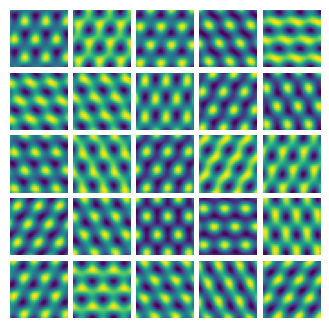

In [4]:
p = rectify(p_) if RECTIFY else p_

ratemaps = compute_ratemaps(r[:, 0], r[:, 1], p, bins=BINS)

# ratemaps are (n_units, bins_x, bins_y), so imshow renders them transposed. Harmless
# for grid patterns, which are symmetric under it -- see KNOWN_ISSUES.md.
fig, _ = ratemap_collage(ratemaps, rows=5, cols=5, figsize=(4, 4))
fig.savefig(FIGURE_DIR / "RoU_ratemaps.svg", dpi=300, transparent=True)
fig.savefig(FIGURE_DIR / "RoU_ratemaps.png", dpi=300, transparent=True)

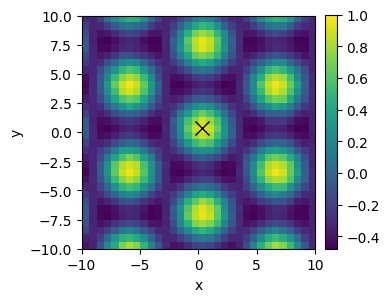

In [5]:
# Similarity of the population vector at the reference bin against every other bin.
# For skew-symmetric generators all population vectors share a norm, so this dot
# product is the cosine similarity of Eq. 3, and it depends only on displacement.
a = BINS // 2
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centres = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(4, 4))
# .T because similarity is indexed (bins_x, bins_y) and imshow wants (row=y, col=x).
plt.imshow(
    similarity.T,
    vmax=1,
    extent=(-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE),
    origin="lower",
)
plt.plot(centres[a], centres[a], "kx", markersize=10)  # the reference bin centre
plt.colorbar(fraction=0.046, pad=0.04)
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "correlation.svg", dpi=300, transparent=True)
plt.savefig(FIGURE_DIR / "correlation.png", dpi=300, transparent=True)

max |empirical - Eq. 4|          = 5.32e-06
max |binned ratemaps - Eq. 4|    = 7.86e-02  (within-bin averaging)


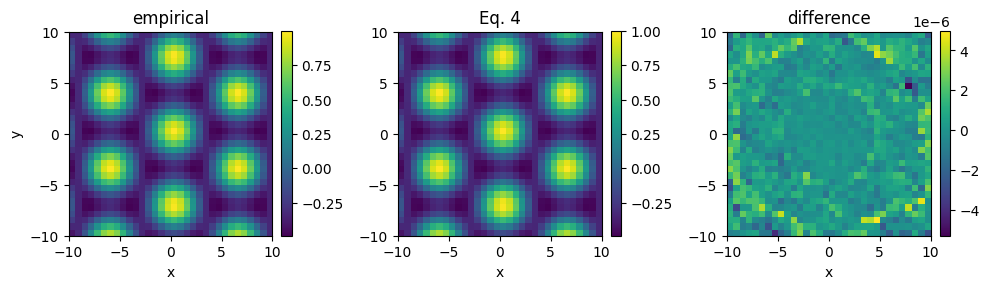

In [6]:
# The similarity above is empirical, and Eq. 4 (App. F) gives it in closed form. With
# the canonical p0 = R^T 1/sqrt(N) the coefficients are uniform at alpha_0,i^2 = 1/N:
#     C(dx, dy) = sum_i (2/N) cos(lambda_ix dx + lambda_iy dy)
# It is a function of displacement alone and is independent of R -- the invariance the
# framework rests on. Evaluate the model *at the bin centres* to compare: the ratemaps
# above average ~24 random samples across a 0.625-wide bin, and that within-bin
# averaging, not any model error, is what separates them.
N = len(Gx)
X, Y = np.meshgrid(centres, centres, indexing="ij")
grid_positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    p_grid = model(grid_positions, p0).numpy()

empirical = compute_similarity(p_grid.T.reshape(N, BINS, BINS), ref_bin=(a, a))

dx = centres[:, None] - centres[a]
dy = centres[None, :] - centres[a]
closed_form = sum((2 / N) * np.cos(np.cos(phi[i]) * dx + np.sin(phi[i]) * dy) for i in range(len(phi)))

print(f"max |empirical - Eq. 4|          = {np.nanmax(np.abs(empirical - closed_form)):.2e}")
print(f"max |binned ratemaps - Eq. 4|    = {np.nanmax(np.abs(similarity - closed_form)):.2e}  (within-bin averaging)")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, img, title in zip(
    axs,
    [empirical.T, closed_form.T, (empirical - closed_form).T],
    ["empirical", "Eq. 4", "difference"],
):
    im = ax.imshow(img, extent=(-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE), origin="lower")
    ax.set_title(title)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "RoU_similarity_vs_closed_form.svg", dpi=300, transparent=True)